# Rossmann Retail — Data Overview and SQL Integration


Run the active cells from top to bottom using the Rossmann project's `.venv` kernel. The workflow is: inspect the CSV data, interpret missing values, import the two source tables into SQLite, and join them with SQL. 

## 1. Check the Python environment and import analysis packages

The Python executable should belong to the `.venv` directory in the Rossmann project.

In [56]:
import sys
from pathlib import Path
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder, TargetEncoder

from sklearn.base import clone
from sklearn.model_selection import KFold

print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)


Python executable: c:\Users\moonp\Documents\Beruflich\Machine Learning Projekte\Rossmann_retail\.venv\Scripts\python.exe
Python version: 3.14.7
Pandas version: 3.1.0
Scikit-learn version: 1.9.1


## 2. Locate the data directory

Place the extracted CSV files in `data/raw` within the project. This cell supports starting the notebook from either the project directory or its `notebooks` subdirectory.

In [3]:
# Determine the project directory.
# The notebook normally starts in the project directory or in "notebooks".
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"

print("Data directory:", DATA_DIR.resolve())


Data directory: C:\Users\moonp\Documents\Beruflich\Machine Learning Projekte\Rossmann_retail\data\raw


## 3. Load the source data

Parse `Date` as a date and read `StateHoliday` as a string so that its codes have a consistent representation. Keep the original CSV files unchanged.

### Data source

This notebook uses `train.csv` and `store.csv` from
[Rossmann Store Sales](https://www.kaggle.com/competitions/rossmann-store-sales)
by FlorianKnauer and Will Cukierski (Kaggle, 2015). The files provide
historical daily sales and store metadata.

In [4]:
# Load the CSV files.
train = pd.read_csv(
    DATA_DIR / "train.csv",
    parse_dates=["Date"],
    dtype={"StateHoliday": "string"},
)

stores = pd.read_csv(DATA_DIR / "store.csv")


## 4. Inspect dataset dimensions, date range, and sample rows

In [ ]:
print("Sales data — rows and columns:", train.shape)
print("Store data — rows and columns:", stores.shape)

print(
    "Date range:",
    train["Date"].min().date(),
    "to",
    train["Date"].max().date(),
)

print("Number of stores in the sales data:", train["Store"].nunique())



Sales data — rows and columns: (1017209, 9)
Store data — rows and columns: (1115, 10)
Date range: 2013-01-01 to 2015-07-31
Number of stores in the sales data: 1115


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


## 5. Inspect data types, missing values, and duplicate keys

Keep missing values and zero-sales records at this stage. Their meaning will guide any later treatment.

In [6]:
def overview(df):
    '''
    Erstelle einen Überblick über einige wichtige Eigenschaften der Spalten eines DataFrames.
    VARs
        df: Der zu betrachtende DataFrame
    RETURNS:
        None
    '''
    df = df.copy()
    display(pd.DataFrame({'dtype': df.dtypes,                                   # Dtypes
                          'total': df.count(),                                  # Anzahl valider Einträge
                          'missing_n': df.isna().sum(),                         # Anzahl nan-Einträge
                          'missing_%': df.isna().mean()*100,                    # Anteil fehlender Daten in %
                          'uniques_n': df.nunique(),                            # Kardinalität (Anzahl einzigartiger Werte)
                          'uniques': [df[col].unique() for col in df.columns]   # Auflistung einzigartiger Werte
                         }))

In [7]:
overview(train)
overview(stores)

print(
    "Duplicate store-date combinations:",
    train.duplicated(subset=["Store", "Date"]).sum(),
)

print(
    "Duplicate store IDs in store.csv:",
    stores.duplicated(subset=["Store"]).sum(),
)

,dtype,total,missing_n,missing_%,uniques_n,uniques
Store,int64,1017209,0,0.0,1115,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
DayOfWeek,int64,1017209,0,0.0,7,"[5, 4, 3, 2, 1, 7, 6]"
Date,datetime64[us],1017209,0,0.0,942,"[2015-07-31 00:00:00, 2015-07-30 00:00:00, 201..."
Sales,int64,1017209,0,0.0,21734,"[5263, 6064, 8314, 13995, 4822, 5651, 15344, 8..."
Customers,int64,1017209,0,0.0,4086,"[555, 625, 821, 1498, 559, 589, 1414, 833, 687..."
Open,int64,1017209,0,0.0,2,"[1, 0]"
Promo,int64,1017209,0,0.0,2,"[1, 0]"
StateHoliday,string,1017209,0,0.0,4,"[0, a, b, c]"
SchoolHoliday,int64,1017209,0,0.0,2,"[1, 0]"


,dtype,total,missing_n,missing_%,uniques_n,uniques
Store,int64,1115,0,0.000000,1115,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
StoreType,str,1115,0,0.000000,4,"[c, a, d, b]"
Assortment,str,1115,0,0.000000,3,"[a, c, b]"
CompetitionDistance,float64,1112,3,0.269058,654,"[1270.0, 570.0, 14130.0, 620.0, 29910.0, 310.0..."
CompetitionOpenSinceMonth,float64,761,354,31.748879,12,"[9.0, 11.0, 12.0, 4.0, 10.0, 8.0, nan, 3.0, 6...."
CompetitionOpenSinceYear,float64,761,354,31.748879,23,"[2008.0, 2007.0, 2006.0, 2009.0, 2015.0, 2013...."
Promo2,int64,1115,0,0.000000,2,"[0, 1]"
Promo2SinceWeek,float64,571,544,48.789238,24,"[nan, 13.0, 14.0, 1.0, 45.0, 40.0, 26.0, 22.0,..."
Promo2SinceYear,float64,571,544,48.789238,7,"[nan, 2010.0, 2011.0, 2012.0, 2009.0, 2014.0, ..."
PromoInterval,str,571,544,48.789238,3,"[nan, Jan,Apr,Jul,Oct, Feb,May,Aug,Nov, Mar,Ju..."


Duplicate store-date combinations: 0
Duplicate store IDs in store.csv: 0


## 6. Check whether missing Promo2 details correspond to non-participation

`Promo2 = 0` indicates that the store does not participate. In the results obtained so far, all 544 non-participating stores lack the three detail fields, while all 571 participating stores have complete details. These missing values are therefore not applicable for non-participants. Leave the source values unchanged for now.

In [8]:
promo_check = stores.groupby("Promo2").agg(
    store_count=("Store", "size"),
    missing_start_week=("Promo2SinceWeek", lambda s: s.isna().sum()),
    missing_start_year=("Promo2SinceYear", lambda s: s.isna().sum()),
    missing_interval=("PromoInterval", lambda s: s.isna().sum()),
)

display(promo_check)


,store_count,missing_start_week,missing_start_year,missing_interval
Promo2,,,,
0,544,544,544,544
1,571,0,0,0


## 7. Import the two source tables into SQLite

The database is stored at `data/rossmann.sqlite`. Re-running this cell replaces the two imported tables and recreates their unique indexes. The CSV source files remain unchanged.

The indexes enforce one sales row per store and date and one store record per store ID.

In [ ]:
DB_PATH = PROJECT_ROOT / "data" / "rossmann.sqlite"

# Create an engine for the local SQLite database.
database_url = URL.create(
    drivername="sqlite+pysqlite",
    database=str(DB_PATH.resolve()),
)

engine = create_engine(database_url)

# Import the source tables and enforce unique keys.
with engine.begin() as connection:
    train.to_sql(
        "sales",
        con=connection,
        if_exists="replace",
        index=False,
        chunksize=10000,
    )

    stores.to_sql(
        "stores",
        con=connection,
        if_exists="replace",
        index=False,
    )

    connection.execute(text("""
        CREATE UNIQUE INDEX ux_sales_store_date
        ON sales (Store, Date)
    """))

    connection.execute(text("""
        CREATE UNIQUE INDEX ux_stores_store
        ON stores (Store)
    """))

print("Database ready:", DB_PATH)

Database ready: c:\Users\moonp\Documents\Beruflich\Machine Learning Projekte\Rossmann_retail\data\rossmann.sqlite


## 8. Join sales and store data using SQL

The database performs the left join. Pandas reads the resulting rows for subsequent analysis and visualization. Check that every sales row has a matching store record and that the row count is unchanged.

For the source files inspected so far, the expected shape is `(1017209, 18)`.

In [ ]:
query = """
SELECT
    s.*,
    f.StoreType,
    f.Assortment,
    f.CompetitionDistance,
    f.CompetitionOpenSinceMonth,
    f.CompetitionOpenSinceYear,
    f.Promo2,
    f.Promo2SinceWeek,
    f.Promo2SinceYear,
    f.PromoInterval
FROM sales AS s
LEFT JOIN stores AS f
    ON s.Store = f.Store
"""

with engine.connect() as connection:
    # Check that every sales row has a matching store record.
    unmatched = connection.execute(text("""
        SELECT COUNT(*)
        FROM sales AS s
        LEFT JOIN stores AS f ON s.Store = f.Store
        WHERE f.Store IS NULL
    """)).scalar_one()

    assert unmatched == 0, (
        "Some stores have no matching store records."
    )

    # Read the SQL query result into a DataFrame.
    df = pd.read_sql_query(
        text(query),
        con=connection,
        parse_dates=["Date"],
        dtype={"StateHoliday": "string"},
    )

assert len(df) == len(train), "The row count has changed."

print("Joined dataset:", df.shape)





Joined dataset: (1017209, 18)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


## 9. Validate opening status and sales


In [11]:
opening_query = text("""
SELECT
    Open AS open_flag,
    COUNT(*) AS recorded_store_days,
    SUM(CASE WHEN Sales = 0 THEN 1 ELSE 0 END) AS zero_sales_days,
    SUM(CASE WHEN Sales > 0 THEN 1 ELSE 0 END) AS positive_sales_days,
    SUM(CASE WHEN Sales < 0 THEN 1 ELSE 0 END) AS negative_sales_days,
    ROUND(AVG(Sales), 2) AS average_sales
FROM sales
GROUP BY Open
ORDER BY Open
""")

with engine.connect() as connection:
    opening_summary = pd.read_sql_query(opening_query, connection)

display(opening_summary)

,open_flag,recorded_store_days,zero_sales_days,positive_sales_days,negative_sales_days,average_sales
0,0,172817,172817,0,0,0.00
1,1,844392,54,844338,0,6955.51


In [ ]:
zero_sales_query = text("""
SELECT
    Store,
    Date,
    Sales,
    Customers,
    Open,
    DayOfWeek,
    Promo,
    StateHoliday,
    SchoolHoliday
FROM sales
WHERE Open = 1 AND Sales = 0
ORDER BY Date, Store
""")

with engine.connect() as connection:
    open_zero_sales = pd.read_sql_query(
        zero_sales_query,
        connection,
        parse_dates=["Date"],
    )

print("Open store-days with zero sales:", len(open_zero_sales))
print(
    "Of these, days with positive customer counts:",
    (open_zero_sales["Customers"] > 0).sum(),
)




Open store-days with zero sales: 54
Of these, days with positive customer counts: 2


,Store,Date,Sales,Customers,Open,DayOfWeek,Promo,StateHoliday,SchoolHoliday
0,762,2013-01-17,0,0,1,4,0,0,0
1,232,2013-01-24,0,0,1,4,1,0,0
2,339,2013-01-30,0,0,1,3,0,0,0
3,339,2013-01-31,0,0,1,4,0,0,0
4,259,2013-02-07,0,0,1,4,1,0,0
5,353,2013-03-16,0,0,1,6,0,0,0
6,948,2013-04-25,0,5,1,4,1,0,0
7,589,2013-04-29,0,0,1,1,1,0,0
8,364,2013-05-07,0,0,1,2,0,0,0
9,364,2013-05-08,0,0,1,3,0,0,0


In [13]:
# Inspect zero-sales records with positive customer counts.
display(
    open_zero_sales.loc[open_zero_sales["Customers"] > 0]
)

,Store,Date,Sales,Customers,Open,DayOfWeek,Promo,StateHoliday,SchoolHoliday
6,948,2013-04-25,0,5,1,4,1,0,0
29,1100,2014-04-29,0,3,1,2,1,0,0


## 10. Check store-level temporal coverage

In [14]:
coverage_query = text("""
SELECT
    Store AS store_id,
    COUNT(DISTINCT Date) AS recorded_days,
    MIN(Date) AS first_recorded_date,
    MAX(Date) AS last_recorded_date
FROM sales
GROUP BY Store
ORDER BY recorded_days, Store
""")

with engine.connect() as conn:
    store_coverage = pd.read_sql_query(
        coverage_query,
        conn,
        parse_dates=["first_recorded_date", "last_recorded_date"],
    )

# Count calendar days across the complete dataset period.
expected_days = (
    df["Date"].max().normalize()
    - df["Date"].min().normalize()
).days + 1

# Measure unrecorded days relative to the complete dataset period.
store_coverage["unrecorded_days"] = (
    expected_days - store_coverage["recorded_days"]
)

print("Calendar days in the dataset period:", expected_days)
print(
    "Stores with incomplete coverage:",
    (store_coverage["unrecorded_days"] > 0).sum(),
)

display(store_coverage.head(10))

Calendar days in the dataset period: 942
Stores with incomplete coverage: 181


,store_id,recorded_days,first_recorded_date,last_recorded_date,unrecorded_days
0,13,758,2013-01-01,2015-07-31,184
1,20,758,2013-01-01,2015-07-31,184
2,22,758,2013-01-01,2015-07-31,184
3,32,758,2013-01-01,2015-07-31,184
4,36,758,2013-01-01,2015-07-31,184
5,41,758,2013-01-01,2015-07-31,184
6,46,758,2013-01-01,2015-07-31,184
7,51,758,2013-01-01,2015-07-31,184
8,52,758,2013-01-01,2015-07-31,184
9,58,758,2013-01-01,2015-07-31,184


In [15]:
coverage_distribution_query = text("""
WITH store_day_counts AS (
    SELECT
        Store,
        COUNT(DISTINCT Date) AS recorded_days
    FROM sales
    GROUP BY Store
)
SELECT
    recorded_days,
    :expected_days - recorded_days AS unrecorded_days,
    COUNT(*) AS store_count
FROM store_day_counts
GROUP BY recorded_days
ORDER BY recorded_days
""")

with engine.connect() as connection:
    coverage_distribution = pd.read_sql_query(
        coverage_distribution_query,
        connection,
        params={"expected_days": int(expected_days)},
    )

display(coverage_distribution)

print(
    "Total unrecorded store-days:",
    int(store_coverage["unrecorded_days"].sum()),
)

,recorded_days,unrecorded_days,store_count
0,758,184,180
1,941,1,1
2,942,0,934


Total unrecorded store-days: 33121


In [16]:
monthly_coverage_query = text("""
WITH monthly_counts AS (
    SELECT
        STRFTIME('%Y-%m', Date) AS month,
        COUNT(DISTINCT DATE(Date)) AS recorded_dates,
        COUNT(DISTINCT Store) AS recorded_stores,
        COUNT(*) AS recorded_store_days
    FROM sales
    GROUP BY STRFTIME('%Y-%m', Date)
)
SELECT
    month,
    recorded_dates,
    recorded_stores,
    recorded_store_days,
    :total_stores * recorded_dates
        - recorded_store_days AS unrecorded_store_days
FROM monthly_counts
WHERE recorded_store_days < :total_stores * recorded_dates
ORDER BY month
""")

with engine.connect() as connection:
    monthly_coverage = pd.read_sql_query(
        monthly_coverage_query,
        connection,
        params={"total_stores": int(stores["Store"].nunique())},
    )

display(monthly_coverage)

,month,recorded_dates,recorded_stores,recorded_store_days,unrecorded_store_days
0,2013-01,31,1115,34564,1
1,2014-07,31,935,28985,5580
2,2014-08,31,935,28985,5580
3,2014-09,30,935,28050,5400
4,2014-10,31,935,28985,5580
5,2014-11,30,935,28050,5400
6,2014-12,31,935,28985,5580


### Summary of temporal coverage

The dataset spans 942 calendar days across 1,115 stores. Of these stores,
934 have a record for every day, 180 are missing 184 days each, and one
store is missing a single day.

Of the 33,121 unrecorded store-days, 33,120 fall between July and
December 2014. During these six months, the dataset contains daily
records for 935 stores. The remaining missing store-day occurs in
January 2013.

The monthly sales trend in Section 11 uses a fixed group of 934 stores
with complete coverage to keep the store composition comparable
across months.

## 11. Analyze sales patterns

### 11.1 Monthly sales trend for stores with complete coverage

In [17]:
monthly_sales_query = text("""
WITH complete_stores AS (
    SELECT Store
    FROM sales
    GROUP BY Store
    HAVING COUNT(DISTINCT DATE(Date)) = :expected_days
)
SELECT
    STRFTIME('%Y-%m-01', s.Date) AS month,
    COUNT(*) AS open_store_days,
    AVG(s.Sales) AS average_sales_per_open_store_day
FROM sales AS s
JOIN complete_stores AS c ON s.Store = c.Store
WHERE s.Open = 1
GROUP BY STRFTIME('%Y-%m-01', s.Date)
ORDER BY month
""")

with engine.connect() as connection:
    monthly_sales = pd.read_sql_query(
        monthly_sales_query,
        connection,
        params={"expected_days": int(expected_days)},
        parse_dates=["month"],
    )

print("Months in the analysis:", len(monthly_sales))
display(monthly_sales.head())

Months in the analysis: 31


,month,open_store_days,average_sales_per_open_store_day
0,2013-01-01,24171,6299.049729
1,2013-02-01,22336,6508.534294
2,2013-03-01,23361,7303.536492
3,2013-04-01,23350,6649.044154
4,2013-05-01,22028,7135.796668


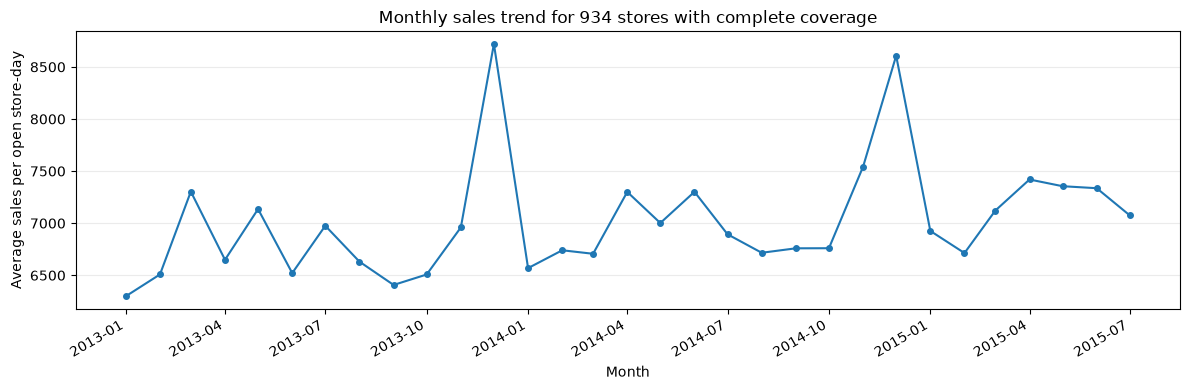

In [18]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    monthly_sales["month"],
    monthly_sales["average_sales_per_open_store_day"],
    marker="o",
    markersize=4,
)

ax.set(
    title="Monthly sales trend for 934 stores with complete coverage",
    xlabel="Month",
    ylabel="Average sales per open store-day",
)
ax.grid(axis="y", alpha=0.25)

fig.autofmt_xdate()
fig.tight_layout()
plt.show()

December had the highest average sales per open store-day in both 2013 and 2014. This recurring peak is consistent with a Christmas shopping effect.

In [19]:
nov_dec = monthly_sales.loc[
    monthly_sales["month"].dt.month.isin([11, 12])
].copy()

nov_dec["year"] = nov_dec["month"].dt.year
nov_dec["month_number"] = nov_dec["month"].dt.month

december_comparison = (
    nov_dec.pivot(
        index="year",
        columns="month_number",
        values="average_sales_per_open_store_day",
    )
    .rename(columns={11: "November", 12: "December"})
)

december_comparison["December vs. November (%)"] = 100 * (
    december_comparison["December"] / december_comparison["November"] - 1
)

display(december_comparison.round(2))

month_number,November,December,December vs. November (%)
year,,,
2013,6959.44,8720.40,25.30
2014,7542.69,8607.26,14.11


### 11.2 Sales by weekday and promotion status

In [20]:
weekday_promo_query = text("""
WITH complete_stores AS (
    SELECT Store
    FROM sales
    GROUP BY Store
    HAVING COUNT(DISTINCT DATE(Date)) = :expected_days
)
SELECT
    s.DayOfWeek AS day_of_week,
    s.Promo AS promo_flag,
    COUNT(*) AS open_store_days,
    AVG(s.Sales) AS average_sales_per_open_store_day
FROM sales AS s
JOIN complete_stores AS c ON s.Store = c.Store
WHERE s.Open = 1
GROUP BY s.DayOfWeek, s.Promo
ORDER BY s.DayOfWeek, s.Promo
""")

with engine.connect() as connection:
    weekday_promo = pd.read_sql_query(
        weekday_promo_query,
        connection,
        params={"expected_days": int(expected_days)},
    )

weekday_labels = {
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday",
    7: "Sunday",
}

weekday_promo["weekday"] = weekday_promo["day_of_week"].map(weekday_labels)
weekday_promo["promotion"] = weekday_promo["promo_flag"].map({
    0: "No promotion",
    1: "Promotion",
})

display(
    weekday_promo[
        ["weekday", "promotion", "open_store_days", "average_sales_per_open_store_day"]
    ].round(2)
)

,weekday,promotion,open_store_days,average_sales_per_open_store_day
0,Monday,No promotion,52343,6282.66
1,Monday,Promotion,66923,9894.89
2,Tuesday,No promotion,57792,5790.41
3,Tuesday,Promotion,66978,8380.92
4,Wednesday,No promotion,56808,5660.04
5,Wednesday,Promotion,66120,7765.16
6,Thursday,No promotion,52200,5812.02
7,Thursday,Promotion,64679,7685.17
8,Friday,No promotion,57255,6391.51
9,Friday,Promotion,62556,7792.89


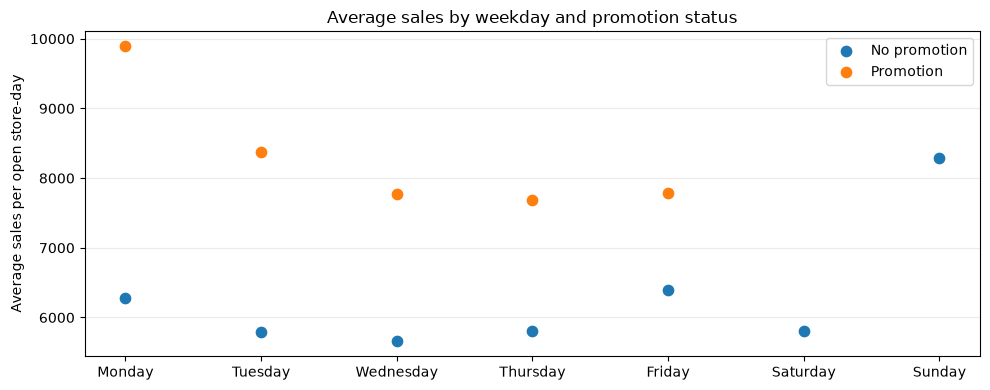

In [21]:
fig, ax = plt.subplots(figsize=(10, 4))

for promotion, group in weekday_promo.groupby("promotion"):
    ax.scatter(
        group["day_of_week"],
        group["average_sales_per_open_store_day"],
        label=promotion,
        s=55,
    )

ax.set_xticks(list(weekday_labels), list(weekday_labels.values()))
ax.set(
    title="Average sales by weekday and promotion status",
    ylabel="Average sales per open store-day",
)
ax.grid(axis="y", alpha=0.25)
ax.legend()

fig.tight_layout()
plt.show()

### 11.3 Promotion frequency and sales in November and December

In [22]:
nov_dec_promo_query = text("""
WITH complete_stores AS (
    SELECT Store
    FROM sales
    GROUP BY Store
    HAVING COUNT(DISTINCT DATE(Date)) = :expected_days
)
SELECT
    STRFTIME('%Y-%m', s.Date) AS month,
    COUNT(*) AS open_store_days,
    SUM(s.Promo) AS promotion_store_days,
    ROUND(100.0 * AVG(s.Promo), 2) AS promotion_share_pct,
    ROUND(AVG(CASE WHEN s.Promo = 0 THEN s.Sales END), 2)
        AS average_sales_without_promotion,
    ROUND(AVG(CASE WHEN s.Promo = 1 THEN s.Sales END), 2)
        AS average_sales_with_promotion
FROM sales AS s
JOIN complete_stores AS c ON s.Store = c.Store
WHERE s.Open = 1
  AND STRFTIME('%Y-%m', s.Date) IN (
      '2013-11', '2013-12', '2014-11', '2014-12'
  )
GROUP BY STRFTIME('%Y-%m', s.Date)
ORDER BY month
""")

with engine.connect() as connection:
    nov_dec_promo = pd.read_sql_query(
        nov_dec_promo_query,
        connection,
        params={"expected_days": int(expected_days)},
    )

display(nov_dec_promo)

,month,open_store_days,promotion_store_days,promotion_share_pct,average_sales_without_promotion,average_sales_with_promotion
0,2013-11,23881,9265,38.80,6289.75,8015.92
1,2013-12,22550,9340,41.42,7282.37,10754.27
2,2014-11,22964,14010,61.01,6259.69,8362.67
3,2014-12,23467,9340,39.80,7414.99,10410.61


### 11.4 Summary of findings

The analysis covers 934 stores with complete records from January 2013
to July 2015. Sales are measured per open store-day, including open days
with zero sales.

**Seasonality.** December had the highest average sales per open store-day
in both 2013 and 2014. The recurring peak is consistent with higher demand
during the Christmas shopping season.

**Weekdays and promotions.** From Monday through Friday, average sales
were higher on days with a promotion. The observed difference ranged from
+21.9% on Fridays to +57.5% on Mondays. Sunday sales averaged 8,282.49
across 3,487 open store-days, compared with 124,508 open store-days on
Saturdays.

**November and December comparison**

| Measure | 2013 | 2014 |
|---|---:|---:|
| Change in average sales per open store-day | approx. +25% | approx. +14% |
| Change in average sales without a promotion | +15.8% | +18.5% |
| Change in average sales with a promotion | +34.2% | +24.5% |
| Share of open store-days with a promotion | 38.80% → 41.42% | 61.01% → 39.80% |

December sales rose in both promotion groups in both years. In 2014,
this increase coincided with a 21.21 percentage point decline in the
share of promotion days. The pattern highlights calendar timing and
promotion status as relevant variables for the forecasting stage.

## 12. Build a sales forecasting baseline

### 12.1 Split the data chronologically

In [23]:
validation_days = 42
last_date = df["Date"].max().normalize()
validation_start = last_date - pd.Timedelta(days=validation_days - 1)

model_train = df.loc[df["Date"] < validation_start].copy()
model_validation = df.loc[df["Date"] >= validation_start].copy()

for name, data in [
    ("Training", model_train),
    ("Validation", model_validation),
]:
    print(
        f"{name}: {data['Date'].min().date()} to "
        f"{data['Date'].max().date()} | "
        f"{len(data):,} rows | {data['Store'].nunique():,} stores"
    )

Training: 2013-01-01 to 2015-06-19 | 970,379 rows | 1,115 stores
Validation: 2015-06-20 to 2015-07-31 | 46,830 rows | 1,115 stores


### 12.2 Predict sales using historical store and weekday averages

In [24]:
open_training = model_train.loc[model_train["Open"].eq(1)]

# calculate historical mean for every weekday 
store_weekday_average = (
    open_training.groupby(["Store", "DayOfWeek"])["Sales"]
    .mean()
    .rename("baseline_prediction")
)

store_average = open_training.groupby("Store")["Sales"].mean()
overall_average = open_training["Sales"].mean()

baseline_prediction = model_validation[["Store", "DayOfWeek"]].join(
    store_weekday_average,
    on=["Store", "DayOfWeek"],
    validate="many_to_one",
)["baseline_prediction"]

open_validation = model_validation["Open"].eq(1)

model_validation["baseline_prediction"] = (
    baseline_prediction
    .fillna(model_validation["Store"].map(store_average))
    .fillna(overall_average)
    .where(open_validation, 0.0)
)

### 12.3 Evaluate the baseline

In [25]:
absolute_error = (
    model_validation["Sales"] - model_validation["baseline_prediction"]
).abs()

baseline_metrics = pd.DataFrame({
    "evaluation_group": ["All store-days", "Open store-days"],
    "rows": [len(model_validation), int(open_validation.sum())],
    "mae": [absolute_error.mean(), absolute_error.loc[open_validation].mean()],
})

display(baseline_metrics.round(2))

,evaluation_group,rows,mae
0,All store-days,46830,1078.81
1,Open store-days,40282,1254.18


### 12.4 Summary of the forecasting baseline

A historical-average baseline was created to provide a reference
for evaluating subsequent forecasting models.

**Chronological validation.** The training period covers January 1,
2013 to June 19, 2015. The following 42 days, from June 20 to July 31,
2015, form the validation period. The analysis includes all 1,115 stores.

**Prediction method.** For each open validation store-day, the prediction
is the average sales of the same store and weekday during the training
period. If that combination has no historical observations, the model
uses the store's average sales across open training days, followed by
the overall average across open training store-days.

The opening schedule is assumed to be known in advance. Predicted sales
are set to zero for closed days. All historical averages are calculated
exclusively from the training data.

**Evaluation.** Mean absolute error (MAE) is calculated across all
validation store-days and separately across open store-days. The latter
measures forecast accuracy during trading operations. Both scores are
expressed in the same units as Sales.

The baseline captures differences between stores and weekdays.
Its validation scores provide the benchmark for assessing the additional
value of calendar, trend, and promotion features.

## 13. Train a linear sales forecasting model

### 13.1 Create calendar and trend features

In [ ]:
# adding month and days since start
reference_date = model_train["Date"].min().normalize()

for data in [model_train, model_validation]:
    data["month"] = data["Date"].dt.month
    data["days_since_start"] = (data["Date"] - reference_date).dt.days

categorical_features = ["Store", "DayOfWeek", "month", "StateHoliday"]
numeric_features = ["days_since_start", "Promo", "SchoolHoliday"]

feature_columns = categorical_features + numeric_features

### 13.2 Fit the model and predict validation sales

In [ ]:
# set up preprocessor with different handling of categorical and numerical features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=True),
            categorical_features,
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features,
        ),
    ]
)

# combine preprocessor and ridge model to a pipeline
ridge_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", Ridge(alpha=1.0, solver="lsqr")),
    ]
)

# only use open store days
open_train_mask = model_train["Open"].eq(1)   # ==1
open_validation = model_validation["Open"].eq(1)   # ==1

ridge_model.fit(
    model_train.loc[open_train_mask, feature_columns],
    model_train.loc[open_train_mask, "Sales"],
)

model_validation["ridge_prediction"] = ridge_model.predict(
    model_validation[feature_columns]
)

# Enforce non-negative sales and apply the known opening schedule.
model_validation["ridge_prediction"] = (
    model_validation["ridge_prediction"]
    .clip(lower=0)
    .where(open_validation, 0.0)
)

print("Training completed.")

Training completed.


### 13.3 Compare the regression with the baseline

In [28]:
comparison_rows = []

for model_name, prediction_column in [
    ("Store-weekday baseline", "baseline_prediction"),
    ("Ridge regression", "ridge_prediction"),
]:
    errors = (
        model_validation["Sales"]
        - model_validation[prediction_column]
    ).abs()

    comparison_rows.append({
        "model": model_name,
        "mae_all_store_days": errors.mean(),
        "mae_open_store_days": errors.loc[open_validation].mean(),
    })

model_comparison = pd.DataFrame(comparison_rows)

display(model_comparison.round(2))

,model,mae_all_store_days,mae_open_store_days
0,Store-weekday baseline,1078.81,1254.18
1,Ridge regression,849.52,987.61


### 13.4 Model comparison summary

Ridge regression achieved an MAE of 987.61 on open validation store-days,
compared with 1,254.18 for the historical store-weekday baseline.
This represents an error reduction of approximately 21.3%.

Across all validation store-days, MAE decreased from 1,078.81 to 849.52.
Both methods used the same chronological validation period, from
June 20 to July 31, 2015, and the same known opening schedule.

The regression combines store identity, calendar features, promotion
status, school holidays, and a shared linear time trend.

## 14. Train a random forest model

### 14.1 Prepare the model pipelinemodel_validation

In [ ]:
forest_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1,
            ),
            categorical_features,
        ),
        (
            "numeric",
            "passthrough",
            numeric_features,
        ),
    ]
)

forest_model = Pipeline(
    steps=[
        ("preprocessor", forest_preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=25,
                min_samples_leaf=10,
                max_samples=0.5,
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

### 14.2 Fit the model and predict validation sales

In [ ]:
#open_train_mask = model_train["Open"].eq(1)
#open_validation = model_validation["Open"].eq(1)

print("Training the random forest...")

forest_model.fit(
    model_train.loc[open_train_mask, feature_columns],
    model_train.loc[open_train_mask, "Sales"],
)

model_validation["forest_prediction"] = forest_model.predict(
    model_validation[feature_columns]
)

model_validation["forest_prediction"] = (
    model_validation["forest_prediction"]
    .clip(lower=0)
    .where(open_validation, 0.0)
)

print("Training and prediction completed.")

Training the random forest...
Training and prediction completed.


### 14.3 Compare all forecasting models

In [33]:
comparison_rows = []

for model_name, prediction_column in [
    ("Store-weekday baseline", "baseline_prediction"),
    ("Ridge regression", "ridge_prediction"),
    ("Random forest", "forest_prediction"),
]:
    errors = (
        model_validation["Sales"]
        - model_validation[prediction_column]
    ).abs()

    comparison_rows.append({
        "model": model_name,
        "mae_all_store_days": errors.mean(),
        "mae_open_store_days": errors.loc[open_validation].mean(),
    })

model_comparison = pd.DataFrame(comparison_rows)

display(model_comparison.round(2))

,model,mae_all_store_days,mae_open_store_days
0,Store-weekday baseline,1078.81,1254.18
1,Ridge regression,849.52,987.61
2,Random forest,1439.09,1673.02


### 14.4 Compare training and validation errors

In [ ]:
#open_train_mask = model_train["Open"].eq(1)
#open_validation = model_validation["Open"].eq(1)

# Align training predictions with the corresponding DataFrame rows.
forest_train_prediction = pd.Series(
    forest_model.predict(
        model_train.loc[open_train_mask, feature_columns]
    ),
    index=model_train.index[open_train_mask],
).clip(lower=0)

forest_train_error = (
    model_train.loc[open_train_mask, "Sales"]
    - forest_train_prediction
).abs()

forest_validation_error = (
    model_validation.loc[open_validation, "Sales"]
    - model_validation.loc[open_validation, "forest_prediction"]
).abs()

forest_diagnostics = pd.DataFrame({
    "dataset": ["Training — open days", "Validation — open days"],
    "mae": [
        forest_train_error.mean(),
        forest_validation_error.mean(),
    ],
})

display(forest_diagnostics.round(2))

,dataset,mae
0,Training — open days,1373.67
1,Validation — open days,1673.02


### 14.5 Test target encoding for store identity

Target encoding is used to represent each store by its typical sales level. The encoder combines the store’s average sales on open training days with the overall average. This gives the Random Forest a way to group stores with similar sales levels and learn how sales vary with factors such as weekday and promotion status.

During training, the encoder splits the training data into five folds. It encodes each fold using sales from the other four, so each row’s own sales value is excluded from its encoding. This procedure is called **cross-fitting**. For the later validation period, the encoder uses store averages estimated from the full training set.

To assess the effect of the store encoding, the two Random Forest variants with identical model settings on the same 42 validation days are compared. The primary metric is the **mean absolute error (MAE) on open store-days**.

In [ ]:

other_categorical_features = [
    column for column in categorical_features if column != "Store"
]

target_preprocessor = ColumnTransformer(
    transformers=[
        (
            "store",
            TargetEncoder(
                target_type="continuous",
                cv=KFold(n_splits=5, shuffle=True, random_state=42),
            ),
            ["Store"],
        ),
        (
            "other_categories",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1,
            ),
            other_categorical_features,
        ),
        ("numeric", "passthrough", numeric_features),
    ]
)

forest_target_model = Pipeline(
    steps=[
        ("preprocessor", target_preprocessor),
        ("regressor", clone(forest_model.named_steps["regressor"])),
    ]
)

open_train_mask = model_train["Open"].eq(1)
open_validation = model_validation["Open"].eq(1)

print("Training the random forest with target-encoded stores...")

forest_target_model.fit(
    model_train.loc[open_train_mask, feature_columns],
    model_train.loc[open_train_mask, "Sales"],
)

model_validation["forest_target_prediction"] = forest_target_model.predict(
    model_validation[feature_columns]
)

model_validation["forest_target_prediction"] = (
    model_validation["forest_target_prediction"]
    .clip(lower=0)
    .where(open_validation, 0.0)
)

print("Training and prediction completed.")

Training the random forest with target-encoded stores...
Training and prediction completed.


In [36]:
target_errors = (
    model_validation["Sales"]
    - model_validation["forest_target_prediction"]
).abs()

target_result = pd.DataFrame([{
    "model": "Random forest — target-encoded stores",
    "mae_all_store_days": target_errors.mean(),
    "mae_open_store_days": target_errors.loc[open_validation].mean(),
}])

encoding_comparison = pd.concat(
    [model_comparison, target_result],
    ignore_index=True,
)

display(encoding_comparison.round(2))

,model,mae_all_store_days,mae_open_store_days
0,Store-weekday baseline,1078.81,1254.18
1,Ridge regression,849.52,987.61
2,Random forest,1439.09,1673.02
3,Random forest — target-encoded stores,767.21,891.92


### 14.6 Conclusion

The initial Random Forest achieved an MAE of 1,673.02 on open validation
store-days, compared with 1,254.18 for the baseline and 987.61 for Ridge.
This prompted a focused test of how store identity was represented.

Replacing the ordinal store code with a smoothed estimate of historical
store sales reduced the validation MAE to **891.92**. This is a **46.7%
reduction** compared with the original forest and a **9.7% reduction**
compared with Ridge. Both forest variants used the same tree settings
and were evaluated on the same 42-day validation window.

The target-encoded Random Forest achieved the lowest MAE in the summer
2015 validation period. Section 15 examines whether its advantage over
Ridge holds in other periods.

## 15. Check model performance across validation windows

In [37]:

# stores with complete data
complete_store_ids = store_coverage.loc[
    store_coverage["unrecorded_days"].eq(0), "store_id"
]

models_to_compare = [
    ("Ridge regression", ridge_model, "ridge_prediction"),
    (
        "Random forest with target encoding",
        forest_target_model,
        "forest_target_prediction",
    ),
]

backtest_rows = []

# Evaluate the existing summer forecasts on the common store group.
summer_open = model_validation.loc[
    model_validation["Open"].eq(1)
    & model_validation["Store"].isin(complete_store_ids)
]

for model_name, _, prediction_column in models_to_compare:
    errors = (summer_open["Sales"] - summer_open[prediction_column]).abs()

    backtest_rows.append({
        "window": "2015-06-20 to 2015-07-31",
        "model": model_name,
        "open_store_days": len(summer_open),
        "mae_open_store_days": errors.mean(),
    })

# Fit fresh models using only data available before each earlier window.
for start, end in [
    ("2014-11-20", "2014-12-31"),
    ("2015-04-20", "2015-05-31"),
]:
    start_date = pd.Timestamp(start)
    end_date = pd.Timestamp(end)

    fold_train = model_train.loc[
        model_train["Date"].lt(start_date)
        & model_train["Open"].eq(1)
    ]
    fold_validation = model_train.loc[
        model_train["Date"].between(start_date, end_date)
        & model_train["Open"].eq(1)
        & model_train["Store"].isin(complete_store_ids)
    ]

    print(f"Evaluating {start} to {end}...")

    for model_name, model_template, _ in models_to_compare:
        fold_model = clone(model_template)
        fold_model.fit(fold_train[feature_columns], fold_train["Sales"])

        predictions = pd.Series(
            fold_model.predict(fold_validation[feature_columns]),
            index=fold_validation.index,
        ).clip(lower=0)

        errors = (fold_validation["Sales"] - predictions).abs()

        backtest_rows.append({
            "window": f"{start} to {end}",
            "model": model_name,
            "open_store_days": len(fold_validation),
            "mae_open_store_days": errors.mean(),
        })

backtest_results = pd.DataFrame(backtest_rows).sort_values(
    ["window", "mae_open_store_days"]
)

display(backtest_results.round(2))

Evaluating 2014-11-20 to 2014-12-31...
Evaluating 2015-04-20 to 2015-05-31...


,window,model,open_store_days,mae_open_store_days
2,2014-11-20 to 2014-12-31,Ridge regression,31905,1526.01
3,2014-11-20 to 2014-12-31,Random forest with target encoding,31905,1760.43
5,2015-04-20 to 2015-05-31,Random forest with target encoding,31077,956.69
4,2015-04-20 to 2015-05-31,Ridge regression,31077,1079.17
1,2015-06-20 to 2015-07-31,Random forest with target encoding,33779,892.66
0,2015-06-20 to 2015-07-31,Ridge regression,33779,993.25


### Conclusion


Ridge regression and the target-encoded random forest were evaluated on open store-days across three 42-day validation windows, using the same 934 stores with complete coverage.

The random forest achieved lower MAE in spring and summer 2015, while Ridge performed better in the November–December 2014 window. Both models had their highest MAE in that window. With equal weight given to each window, their average MAEs were nearly identical at 1,199.48 for Ridge and 1,203.26 for the random forest. The model ranking therefore depended on the validation period.

## 16. Forecast Error Analysis and Baseline Comparison

### 16.1 Winter Forecast Error Analysis

In [ ]:
winter_start = pd.Timestamp("2014-11-20")
winter_end = pd.Timestamp("2014-12-31")

winter_train = model_train.loc[
    model_train["Date"].lt(winter_start)   # lt: less than
    & model_train["Open"].eq(1)
]

winter_validation = model_train.loc[
    model_train["Date"].between(winter_start, winter_end)
    & model_train["Open"].eq(1)
    & model_train["Store"].isin(complete_store_ids)
]

winter_predictions = winter_validation[["Date", "Store", "Sales"]].copy()

for _, pipeline, prediction_column in models_to_compare:
    model = clone(pipeline)
    model.fit(winter_train[feature_columns], winter_train["Sales"])
    predictions = model.predict(winter_validation[feature_columns])
    winter_predictions[prediction_column] = predictions.clip(0, None)

,model,mae,mean_error
0,Ridge regression,1526.01,-10.78
1,Random forest with target encoding,1760.43,-333.85


<Axes: title={'center': 'Actual and predicted sales in November and December 2014'}, xlabel='Date', ylabel='Average sales per open store-day'>

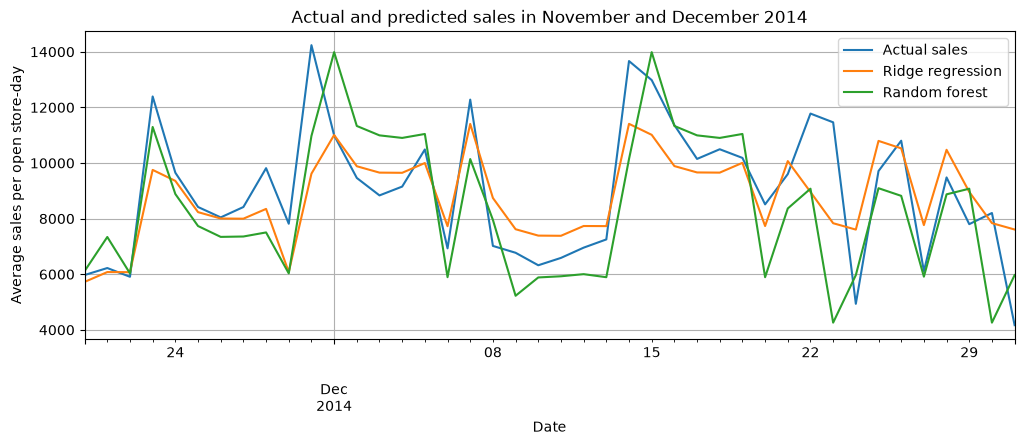

In [39]:
error_summary = []

for model_name, _, prediction_column in models_to_compare:
    errors = winter_predictions[prediction_column] - winter_predictions["Sales"]

    error_summary.append({
        "model": model_name,
        "mae": errors.abs().mean(),
        "mean_error": errors.mean(),
    })

display(pd.DataFrame(error_summary).round(2))

daily_winter_sales = (
    winter_predictions.groupby("Date")[
        ["Sales", "ridge_prediction", "forest_target_prediction"]
    ]
    .mean()
    .rename(columns={
        "Sales": "Actual sales",
        "ridge_prediction": "Ridge regression",
        "forest_target_prediction": "Random forest",
    })
)

daily_winter_sales.plot(
    figsize=(12, 4),
    title="Actual and predicted sales in November and December 2014",
    xlabel="Date",
    ylabel="Average sales per open store-day",
    grid=True,
)

### 16.2 Days with the largest sales underestimation

In [40]:
daily_store_context = winter_validation.groupby("Date").agg(
    open_stores=("Store", "size"),
    promo_share=("Promo", "mean"),
)

daily_winter_diagnostics = daily_winter_sales.join(daily_store_context)

daily_winter_diagnostics["promo_share_pct"] = (
    daily_winter_diagnostics["promo_share"] * 100
)
daily_winter_diagnostics["ridge_mean_error"] = (
    daily_winter_diagnostics["Ridge regression"]
    - daily_winter_diagnostics["Actual sales"]
)
daily_winter_diagnostics["forest_mean_error"] = (
    daily_winter_diagnostics["Random forest"]
    - daily_winter_diagnostics["Actual sales"]
)

display(
    daily_winter_diagnostics
    .nsmallest(6, "forest_mean_error")
    [[
        "open_stores",
        "promo_share_pct",
        "Actual sales",
        "ridge_mean_error",
        "forest_mean_error",
    ]]
    .round(2)
)


,open_stores,promo_share_pct,Actual sales,ridge_mean_error,forest_mean_error
Date,,,,,
2014-12-23,934,0.0,11463.15,-3628.28,-7203.73
2014-12-30,934,0.0,8202.36,-364.28,-3942.94
2014-12-14,16,0.0,13666.88,-2257.65,-3524.39
2014-11-30,17,0.0,14238.59,-4621.84,-3265.09
2014-12-22,934,0.0,11778.00,-2819.68,-2701.68
2014-12-20,934,0.0,8513.12,-779.03,-2619.63


### 16.3 Store-weekday baseline across validation windows

In [41]:
baseline_windows = [
    ("2014-11-20", "2014-12-31", model_train),
    ("2015-04-20", "2015-05-31", model_train),
    ("2015-06-20", "2015-07-31", model_validation),
]

baseline_rows = []

for start, end, validation_source in baseline_windows:
    start_date = pd.Timestamp(start)
    end_date = pd.Timestamp(end)

    history = model_train.loc[
        model_train["Date"].lt(start_date) & model_train["Open"].eq(1)
    ]
    evaluation = validation_source.loc[
        validation_source["Date"].between(start_date, end_date)
        & validation_source["Open"].eq(1)
        & validation_source["Store"].isin(complete_store_ids),
        ["Store", "DayOfWeek", "Sales"],
    ]

    store_weekday_mean = (
        history.groupby(["Store", "DayOfWeek"])["Sales"]
        .mean()
        .rename("store_weekday_mean")
    )
    store_mean = history.groupby("Store")["Sales"].mean()

    baseline_prediction = (
        evaluation.join(store_weekday_mean, on=["Store", "DayOfWeek"])
        ["store_weekday_mean"]
        .fillna(evaluation["Store"].map(store_mean))
        .fillna(history["Sales"].mean())
    )

    baseline_rows.append({
        "window": f"{start} to {end}",
        "model": "Store-weekday baseline",
        "open_store_days": len(evaluation),
        "mae_open_store_days": (baseline_prediction - evaluation["Sales"]).abs().mean(),
    })

backtest_with_baseline = (
    pd.concat([backtest_results, pd.DataFrame(baseline_rows)], ignore_index=True)
    .sort_values(["window", "mae_open_store_days"])
    .reset_index(drop=True)
)

display(backtest_with_baseline.round(2))

,window,model,open_store_days,mae_open_store_days
0,2014-11-20 to 2014-12-31,Ridge regression,31905,1526.01
1,2014-11-20 to 2014-12-31,Random forest with target encoding,31905,1760.43
2,2014-11-20 to 2014-12-31,Store-weekday baseline,31905,2105.63
3,2015-04-20 to 2015-05-31,Random forest with target encoding,31077,956.69
4,2015-04-20 to 2015-05-31,Ridge regression,31077,1079.17
5,2015-04-20 to 2015-05-31,Store-weekday baseline,31077,1213.88
6,2015-06-20 to 2015-07-31,Random forest with target encoding,33779,892.66
7,2015-06-20 to 2015-07-31,Ridge regression,33779,993.25
8,2015-06-20 to 2015-07-31,Store-weekday baseline,33779,1260.55


Both models reduced MAE relative to the store-weekday baseline in all three validation windows. Ridge regression achieved the lowest MAE in November–December 2014, reducing it by 27.5% relative to the baseline. The target-encoded random forest performed best in spring and summer, with reductions of 21.2% and 29.2%, respectively.

Both models underestimated sales on December 22 and 23, when all 934 stores in the evaluation cohort were open. This motivates testing whether a pre-Christmas calendar feature improves forecasts during that period.

## 17. Testing a Pre-Christmas Calendar Feature

### 17.1 Create the calendar feature

In [42]:
def features_with_christmas_week(data):
    dates = data["Date"]
    pre_christmas_week = (
        dates.dt.month.eq(12) & dates.dt.day.between(17, 23)
    )

    return data[feature_columns].assign(
        pre_christmas_week=pre_christmas_week.astype("int8")
    )


X_winter_train = features_with_christmas_week(winter_train)
X_winter_validation = features_with_christmas_week(winter_validation)

### 17.2 Compare Ridge forecasts in the winter window

In [43]:
ridge_christmas = clone(ridge_model)

# Pass the binary calendar feature directly to Ridge.
preprocessor = ridge_christmas.steps[0][1]
preprocessor.set_params(transformers=[
    *preprocessor.transformers,
    ("christmas_week", "passthrough", ["pre_christmas_week"]),
])

ridge_christmas.fit(X_winter_train, winter_train["Sales"])
christmas_predictions = ridge_christmas.predict(X_winter_validation).clip(0, None)

comparison = winter_predictions[["Sales", "ridge_prediction"]].copy()
comparison["ridge_christmas_prediction"] = christmas_predictions

prediction_columns = ["ridge_prediction", "ridge_christmas_prediction"]
absolute_errors = comparison[prediction_columns].sub(
    comparison["Sales"], axis="index"
).abs()

pre_christmas_days = X_winter_validation["pre_christmas_week"].eq(1)

christmas_mae_comparison = pd.DataFrame({
    "Full winter window": absolute_errors.mean(),
    "December 17–23": absolute_errors.loc[pre_christmas_days].mean(),
}).T.rename(columns={
    "ridge_prediction": "Original Ridge",
    "ridge_christmas_prediction": "Ridge with calendar feature",
})

display(christmas_mae_comparison.round(2))

,Original Ridge,Ridge with calendar feature
Full winter window,1526.01,1405.95
December 17–23,2042.36,1924.80


### 17.3 Check the effect in spring and summer

In [44]:
calendar_feature_scores = {
    "2014-11-20 to 2014-12-31": christmas_mae_comparison.loc[
        "Full winter window", "Ridge with calendar feature"
    ],
}

# Refit for the spring and summer windows.
for start, end, validation_source in baseline_windows[1:]:
    start_date = pd.Timestamp(start)
    end_date = pd.Timestamp(end)

    calendar_train = model_train.loc[
        model_train["Date"].lt(start_date) & model_train["Open"].eq(1)
    ]
    calendar_validation = validation_source.loc[
        validation_source["Date"].between(start_date, end_date)
        & validation_source["Open"].eq(1)
        & validation_source["Store"].isin(complete_store_ids)
    ]

    calendar_model = clone(ridge_christmas)
    calendar_model.fit(
        features_with_christmas_week(calendar_train),
        calendar_train["Sales"],
    )
    predictions = calendar_model.predict(
        features_with_christmas_week(calendar_validation)
    ).clip(0, None)

    errors = calendar_validation["Sales"] - predictions
    calendar_feature_scores[f"{start} to {end}"] = errors.abs().mean()

ridge_calendar_backtest = (
    backtest_results.loc[
        backtest_results["model"].eq("Ridge regression"),
        ["window", "open_store_days", "mae_open_store_days"],
    ]
    .set_index("window")
    .rename(columns={"mae_open_store_days": "original_ridge_mae"})
    .sort_index()
)

ridge_calendar_backtest["calendar_feature_mae"] = pd.Series(calendar_feature_scores)
ridge_calendar_backtest["mae_reduction_pct"] = 100 * (
    1 - ridge_calendar_backtest["calendar_feature_mae"]
    / ridge_calendar_backtest["original_ridge_mae"]
)

display(ridge_calendar_backtest.round(2))

,open_store_days,original_ridge_mae,calendar_feature_mae,mae_reduction_pct
window,,,,
2014-11-20 to 2014-12-31,31905,1526.01,1405.95,7.87
2015-04-20 to 2015-05-31,31077,1079.17,1077.93,0.11
2015-06-20 to 2015-07-31,33779,993.25,992.82,0.04


### 17.4 Conclusion

Adding a binary indicator for December 17–23 reduced Ridge MAE from 1,526.01 to 1,405.95 across the full winter window (7.87%) and from 2,042.36 to 1,924.80 during the pre-Christmas week (5.76%). MAE decreased by 0.11% in spring and 0.04% in summer.

The winter result is exploratory because the 2014 forecast errors informed the feature design. Ridge with the calendar feature was selected for the first batch forecasting workflow, while the target-encoded random forest remained the strongest model in the spring and summer windows.

## 18. Batch Forecasting and Project Documentation


### 18.1 Build shared features for training and prediction

In [51]:
import sys
from pathlib import Path

# Find the project root when the notebook kernel starts inside notebooks/.
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

# Add the project root to Python's search path so it can import forecast.py.
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Use the same forecasting functions in the notebook and in the terminal.
from forecast import (
    build_forecast_features,
    forecast_input_columns,
    predict_batch,
    read_schedule,
)

# Use the first training date as the origin for days_since_start.
reference_date = model_train["Date"].min().normalize()

In [52]:
winter_forecast_input = winter_validation[forecast_input_columns]
rebuilt_winter_features = build_forecast_features(
    winter_forecast_input, reference_date
)

pd.testing.assert_frame_equal(
    rebuilt_winter_features,
    X_winter_validation,
    check_dtype=False,
)

print("Feature check passed: rebuilt features match section 17.")
display(rebuilt_winter_features.head())

Feature check passed: rebuilt features match section 17.


,Store,DayOfWeek,month,StateHoliday,days_since_start,Promo,SchoolHoliday,pre_christmas_week
236380,1,3,12,0,729,0,1,0
236381,2,3,12,0,729,0,1,0
236382,3,3,12,0,729,0,1,0
236383,4,3,12,0,729,0,1,0
236384,5,3,12,0,729,0,1,0


### 18.2 Run a batch forecast from CSV

In [53]:
# create example csv-file
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

batch_dir = project_root / "data" / "batch_demo"
batch_dir.mkdir(parents=True, exist_ok=True)

input_path = batch_dir / "forecast_input.csv"
output_path = batch_dir / "forecast_output.csv"

demo_schedule = model_train.loc[
    model_train["Store"].isin([1, 2, 3])
    & model_train["Date"].between("2014-12-22", "2014-12-26"),
    forecast_input_columns,
].sort_values(["Store", "Date"])

demo_schedule.to_csv(input_path, index=False, date_format="%Y-%m-%d")

In [54]:
# Read the schedule and generate one forecast per store-day.
batch_schedule = read_schedule(input_path)
batch_forecast = predict_batch(batch_schedule, ridge_christmas, reference_date)

# Verify that the demo includes closed store-days and forecasts zero for them.
closed_rows = batch_schedule["Open"].eq(0)
assert closed_rows.any(), "The demo must include at least one closed store-day."
assert batch_forecast.loc[closed_rows, "PredictedSales"].eq(0).all()

# Save the forecast and show the opening status in the notebook preview.
batch_forecast.to_csv(output_path, index=False, date_format="%Y-%m-%d")

print(f"Saved {len(batch_forecast)} forecasts to {output_path.resolve()}")
display(batch_forecast.assign(Open=batch_schedule["Open"]).round(2))

Saved 15 forecasts to C:\Users\moonp\Documents\Beruflich\Machine Learning Projekte\Rossmann_retail\data\batch_demo\forecast_output.csv


C:\Users\moonp\AppData\Local\Temp\ipykernel_19168\547965055.py:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(batch_forecast.assign(Open=batch_schedule["Open"]).round(2))


,Store,Date,PredictedSales,Open
0,1,2014-12-22,8783.72,1
1,1,2014-12-23,7659.35,1
2,1,2014-12-24,4832.89,1
3,1,2014-12-25,0.00,0
4,1,2014-12-26,0.00,0
5,2,2014-12-22,8926.34,1
6,2,2014-12-23,7801.97,1
7,2,2014-12-24,4975.51,1
8,2,2014-12-25,0.00,0
9,2,2014-12-26,0.00,0


### 18.3 Run the batch forecast from the command line

In [57]:
model_path = batch_dir / "ridge_winter_demo.joblib"

joblib.dump(
    {"model": ridge_christmas, "reference_date": reference_date},
    model_path,
)

print(model_path.resolve())

C:\Users\moonp\Documents\Beruflich\Machine Learning Projekte\Rossmann_retail\data\batch_demo\ridge_winter_demo.joblib


### 

### 18.4 Verify the batch forecast

In [59]:
# Compare the CSV generated in the notebook with the one from the terminal.
notebook_forecast = pd.read_csv(output_path, parse_dates=["Date"])
cli_forecast = pd.read_csv(batch_dir / "forecast_cli.csv", parse_dates=["Date"])

pd.testing.assert_frame_equal(notebook_forecast, cli_forecast)

# Verify that training and forecasting are separated by the cutoff date.
assert winter_train["Date"].max() < winter_start
assert cli_forecast["Date"].min() >= winter_start

print("Batch forecast verification passed.")

Batch forecast verification passed.
